# gfbr_nn_pinn: ReLU network + softmax output + MSE to the truth + g1 physics residual

Same network, data and training as `gfbr_nn_naive` (trimmed g1 in, 150 bin masses out, softmax = the simplex constraint). The only change is one extra term in the loss:

`loss = MSE(a, d) + lam * phys`,  `phys = (1/n_rows) * sum_i mask_i * ((K a)_i - g_i)^2`

- `a`: network output (150 masses, sum 1); `d`: the true distribution (label).
- `K a`: the g1 curve that `a` would produce through the known kernel; `g`: the stored trimmed noisy curve (the network input).
- `mask_i`: 1 for the rows MEM uses (points `0..ic` and the 13 zero rows from `iz`), 0 for the dropped rows. `n_rows = sum_i mask_i`. The network size does not change; only the loss ignores the dropped rows.
- `lam`: weight of the physics term. `lam = 0` gives back the naive network.

**Checkpoint.** As in `gfbr_nn_naive`: the weights with the lowest validation MSE against the truth are kept, so the two networks differ only in the training loss.

In [1]:
import os
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

data = np.load("gfbr_data.npz")
R, tau, sigma = data["R"], data["tau"], float(data["sigma"])
N, M = len(tau), len(R)
nzero = int(data["nzero"])

T = lambda key: torch.tensor(data[key], dtype=torch.float32)
K = T("K")                                                # (N, M)
x_train, d_train = T("g1_trim_train"), T("d_train")       # trimmed noisy curves, truth
x_val,   d_val   = T("g1_trim_val"),   T("d_val")

# --- mask of the rows MEM uses: 0..ic and iz..iz+nzero-1 ---
ar = np.arange(N)
def rows_mask(ic, iz):
    ic, iz = np.asarray(ic)[:, None], np.asarray(iz)[:, None]
    return torch.tensor(((ar[None, :] <= ic) | ((ar[None, :] >= iz) & (ar[None, :] < iz + nzero))).astype(np.float32))

mask_train = rows_mask(data["ic_train"], data["iz_train"])
mask_val   = rows_mask(data["ic_val"],   data["iz_val"])
print(N, M, x_train.shape, mask_train.shape, "rows used per curve: %.0f on average" % mask_train.sum(1).mean())

100 150 torch.Size([16384, 100]) torch.Size([16384, 100]) rows used per curve: 76 on average


## Model, loss and training
`phys_loss` is the masked mean squared g1 residual per curve, averaged over the batch. Training is identical to `gfbr_nn_naive` (fixed steps, cosine learning rate, batches from the first `n_train` curves, best-validation checkpoint) except that the loss has the extra term.

In [2]:
def make_model(H=128):
    return nn.Sequential(
        nn.Linear(N, H), nn.ReLU(),
        nn.Linear(H, H), nn.ReLU(),
        nn.Linear(H, M),
        nn.Softmax(dim=-1)        # a_i >= 0, sum(a_i) = 1
    )

def phys_loss(a, x, mask):
    # mean over the used rows of ((K a) - g)^2, one value per curve, then averaged over the batch
    r2 = mask*((a @ K.T) - x)**2
    return (r2.sum(dim=1)/mask.sum(dim=1)).mean()

def train(n_train, seed, lam=1.0, steps=20000, batch=256, lr=1e-3, lr_min=1e-6, eval_every=200):
    torch.manual_seed(seed)
    model = make_model()
    mse = nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr_min)
    x, d, mask = x_train[:n_train], d_train[:n_train], mask_train[:n_train]
    hist = {k: [] for k in ["step", "train_mse", "train_phys", "val_mse", "val_phys"]}
    best_val, best_state = float("inf"), None
    r_mse, r_phys, count = 0.0, 0.0, 0
    for step in range(1, steps + 1):
        idx = torch.randint(0, n_train, (batch,))
        a = model(x[idx])
        l_mse, l_phys = mse(a, d[idx]), phys_loss(a, x[idx], mask[idx])
        loss = l_mse + lam*l_phys
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        r_mse += l_mse.item(); r_phys += l_phys.item(); count += 1
        if step % eval_every == 0:
            with torch.no_grad():
                av = model(x_val); v_mse = mse(av, d_val).item(); v_phys = phys_loss(av, x_val, mask_val).item()
            for k, v in zip(hist, [step, r_mse/count, r_phys/count, v_mse, v_phys]): hist[k].append(v)
            r_mse, r_phys, count = 0.0, 0.0, 0
            if v_mse < best_val:
                best_val = v_mse; best_state = {k: t.clone() for k, t in model.state_dict().items()}
    model.load_state_dict(best_state)
    hist["best_val"] = best_val
    return model, hist

## Train once
`n_train = 8192`, one seed, `lam = 1`. Left: MSE against the truth (train and validation). Right: the physics residual (train and validation).

best validation MSE vs truth: 0.00018946560157928616


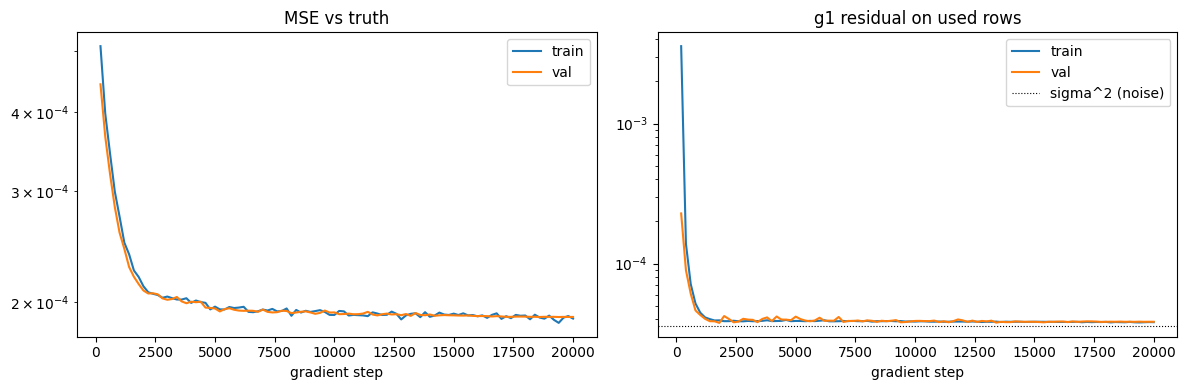

In [3]:
lam = 1.0
model, hist = train(n_train=8192, seed=0, lam=lam)
print("best validation MSE vs truth:", hist["best_val"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].semilogy(hist["step"], hist["train_mse"], label="train"); axes[0].semilogy(hist["step"], hist["val_mse"], label="val")
axes[0].set_title("MSE vs truth"); axes[0].legend()
axes[1].semilogy(hist["step"], hist["train_phys"], label="train"); axes[1].semilogy(hist["step"], hist["val_phys"], label="val")
axes[1].axhline(sigma**2, color='k', lw=0.8, ls=':', label="sigma^2 (noise)"); axes[1].set_title("g1 residual on used rows"); axes[1].legend()
for ax in axes: ax.set_xlabel("gradient step")
plt.tight_layout(); plt.show()

In [4]:
# save the trained weights; to reuse in a fresh session load them instead of retraining
torch.save(model.state_dict(), "gfbr_nn_pinn.pt")
# model = make_model(); model.load_state_dict(torch.load("gfbr_nn_pinn.pt")); model.eval()

## One unimodal and one bimodal curve
The same two curves as in `gfbr_mem` (same `seed`, same random draw): a random validation curve and a random noise draw of the 4 + 16 nm bimodal. Width is the left-side cv of `gfbr_mem` (`left_cv`).

unimodal  true: mode 3.4 nm, left-cv 0.092 | network: mode 3.5 nm, left-cv 0.187
bimodal peak 1: true mass 0.70, mode 4.0 nm, left-cv 0.129 | network mass 0.95, mode 6.3 nm, left-cv 0.135
bimodal peak 2: true mass 0.30, mode 15.7 nm, left-cv 0.122 | network mass 0.05, mode 8.0 nm, left-cv nan


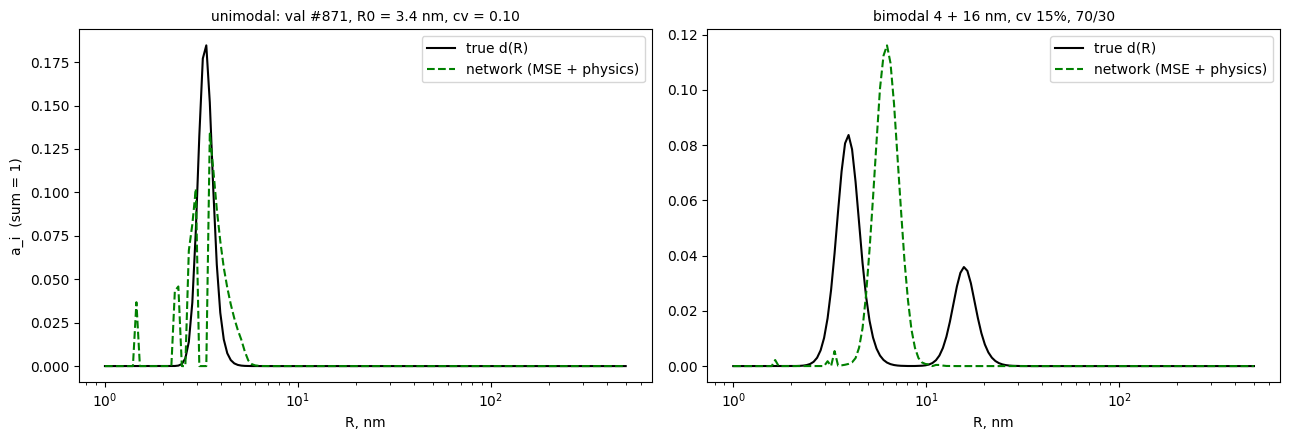

In [5]:
def left_cv(R, p, lo=0.0, hi=np.inf, level=0.5, thr_frac=0.01):
    sel = np.where((R >= lo) & (R < hi))[0]; ip = sel[np.argmax(p[sel])]
    left = np.arange(sel[0], ip + 1); left = left[p[left] > thr_frac*p[ip]]
    for j in range(len(left) - 1):
        y1, y2 = p[left[j]], p[left[j + 1]]
        if y1 <= level*p[ip] <= y2:
            r_half = R[left[j]] + (level*p[ip] - y1)*(R[left[j + 1]] - R[left[j]])/(y2 - y1)
            return R[ip], (R[ip] - r_half)/(1.177*R[ip])
    return R[ip], np.nan

seed = 0
rng = np.random.default_rng(seed)
ku = int(rng.integers(len(data["d_val"])))      # random validation curve (same as gfbr_mem)
kb = int(rng.integers(len(data["d_bi"])))       # random noise draw of the bimodal (same as gfbr_mem)

d_u, x_u = data["d_val"][ku], T("g1_trim_val")[ku]
d_b, x_b = data["d_bi_single"], T("g1_trim_bi")[kb]
with torch.no_grad():
    a_u, a_b = model(x_u[None])[0].numpy(), model(x_b[None])[0].numpy()

print(f"unimodal  true: mode {R[np.argmax(d_u)]*1e9:.1f} nm, left-cv {left_cv(R, d_u)[1]:.3f} | network: mode {R[np.argmax(a_u)]*1e9:.1f} nm, left-cv {left_cv(R, a_u)[1]:.3f}")
split = np.sqrt(float(data["bi_R1"])*float(data["bi_R2"]))
for lab, lo, hi in [("peak 1", 0.0, split), ("peak 2", split, np.inf)]:
    (rt, ct), (rm, cm) = left_cv(R, d_b, lo, hi), left_cv(R, a_b, lo, hi)
    mt, mm = d_b[(R >= lo) & (R < hi)].sum(), a_b[(R >= lo) & (R < hi)].sum()
    print(f"bimodal {lab}: true mass {mt:.2f}, mode {rt*1e9:.1f} nm, left-cv {ct:.3f} | network mass {mm:.2f}, mode {rm*1e9:.1f} nm, left-cv {cm:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].semilogx(R*1e9, d_u, 'k-', label='true d(R)'); axes[0].semilogx(R*1e9, a_u, 'g--', label='network (MSE + physics)')
axes[0].set_title(f"unimodal: val #{ku}, R0 = {data['R0_val'][ku]*1e9:.1f} nm, cv = {data['cv_val'][ku]:.2f}", fontsize=10)
axes[1].semilogx(R*1e9, d_b, 'k-', label='true d(R)'); axes[1].semilogx(R*1e9, a_b, 'g--', label='network (MSE + physics)')
axes[1].set_title("bimodal 4 + 16 nm, cv 15%, 70/30", fontsize=10)
for ax in axes: ax.set_xlabel('R, nm'); ax.legend()
axes[0].set_ylabel('a_i  (sum = 1)')
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig('figures/gfbr_nn_pinn_fits.png', dpi=130); plt.show()

## Random unimodal validation curves
Six validation curves picked at random (no fixed seed: rerun the cell to see others). Title: peak position and cv of the truth, and the MSE of this curve.

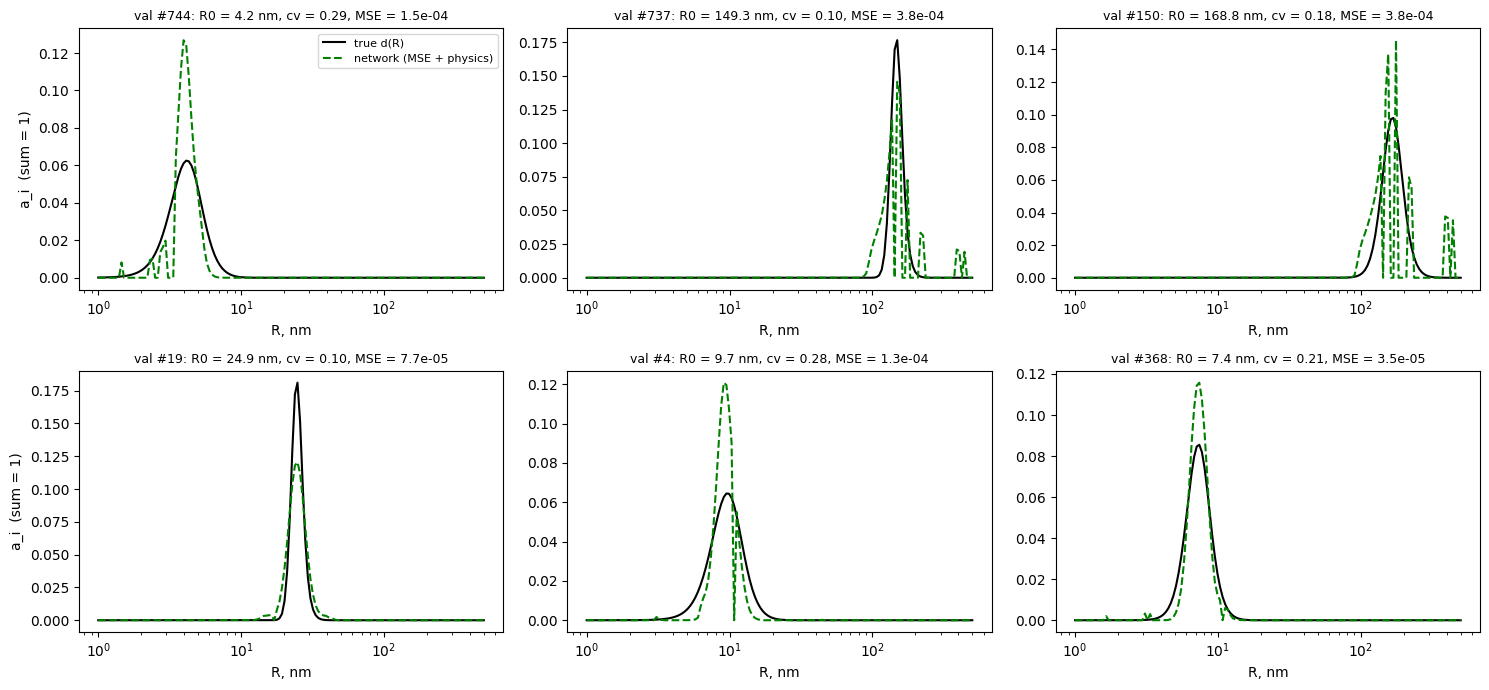

In [9]:
picks = np.random.default_rng().choice(len(d_val), 6, replace=False)
with torch.no_grad():
    pred = model(x_val[picks]).numpy()

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, k, p in zip(axes.flat, picks, pred):
    d_k = d_val[k].numpy()
    ax.semilogx(R*1e9, d_k, 'k-', label='true d(R)'); ax.semilogx(R*1e9, p, 'g--', label='network (MSE + physics)')
    ax.set_title(f"val #{k}: R0 = {data['R0_val'][k]*1e9:.1f} nm, cv = {data['cv_val'][k]:.2f}, MSE = {np.mean((p - d_k)**2):.1e}", fontsize=9)
    ax.set_xlabel('R, nm')
axes[0, 0].legend(fontsize=8); axes[0, 0].set_ylabel('a_i  (sum = 1)'); axes[1, 0].set_ylabel('a_i  (sum = 1)')
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig('figures/gfbr_nn_pinn_random_unimodal.png', dpi=130); plt.show()